In [1]:
import pandas as pd 
import numpy as numpy 
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')


In [2]:
df=pd.read_csv(r"C:\Users\dell\OneDrive\Desktop\PBeL\Synthetic_Financial_datasets_log.csv")

In [3]:
df.head(100000)

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.00,0.00,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.00,0.00,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.00,0.00,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.00,0.00,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.00,0.00,0,0
...,...,...,...,...,...,...,...,...,...,...,...
99995,10,PAYMENT,4020.66,C1410794718,159929.0,155908.34,M1257036576,0.00,0.00,0,0
99996,10,PAYMENT,18345.49,C744303677,6206.0,0.00,M1785344556,0.00,0.00,0,0
99997,10,CASH_IN,183774.91,C104331851,39173.0,222947.91,C36392889,54925.05,0.00,0,0
99998,10,CASH_OUT,82237.17,C707662966,6031.0,0.00,C1553004158,592635.66,799140.46,0,0


In [4]:
df.info

<bound method DataFrame.info of          step      type     amount     nameOrig  oldbalanceOrg  \
0           1   PAYMENT    9839.64  C1231006815      170136.00   
1           1   PAYMENT    1864.28  C1666544295       21249.00   
2           1  TRANSFER     181.00  C1305486145         181.00   
3           1  CASH_OUT     181.00   C840083671         181.00   
4           1   PAYMENT   11668.14  C2048537720       41554.00   
...       ...       ...        ...          ...            ...   
1048570    95  CASH_OUT  132557.35  C1179511630      479803.00   
1048571    95   PAYMENT    9917.36  C1956161225       90545.00   
1048572    95   PAYMENT   14140.05  C2037964975       20545.00   
1048573    95   PAYMENT   10020.05  C1633237354       90605.00   
1048574    95   PAYMENT   11450.03  C1264356443       80584.95   

         newbalanceOrig     nameDest  oldbalanceDest  newbalanceDest  isFraud  \
0             160296.36  M1979787155            0.00            0.00        0   
1            

In [5]:
df.shape

(1048575, 11)

In [6]:
df.columns

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='str')

In [7]:
df["isFraud"].value_counts()

isFraud
0    1047433
1       1142
Name: count, dtype: int64

In [8]:
df["isFlaggedFraud"].value_counts()

isFlaggedFraud
0    1048575
Name: count, dtype: int64

In [9]:
df.isnull().sum()

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

In [10]:
round(df["isFraud"].value_counts()[1]/df.shape[0]*100,4)

np.float64(0.1089)

In [11]:
df['type'].value_counts()

type
CASH_OUT    373641
PAYMENT     353873
CASH_IN     227130
TRANSFER     86753
DEBIT         7178
Name: count, dtype: int64

Text(0, 0.5, 'Count')

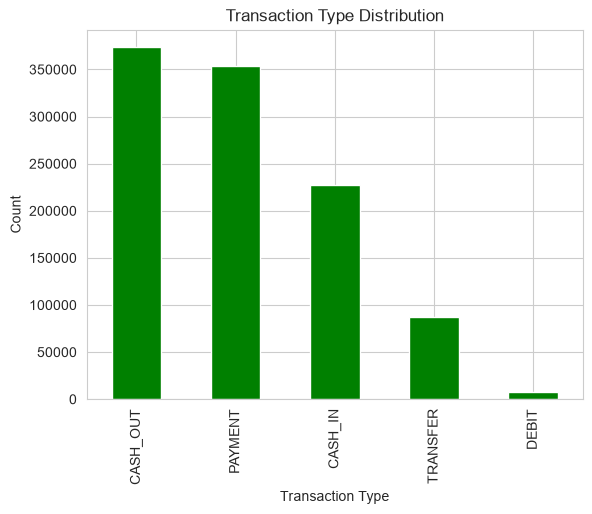

In [12]:
df["type"].value_counts().plot(kind="bar",color="green")
plt.title("Transaction Type Distribution")
plt.xlabel("Transaction Type")
plt.ylabel("Count")

Text(0, 0.5, 'Count')

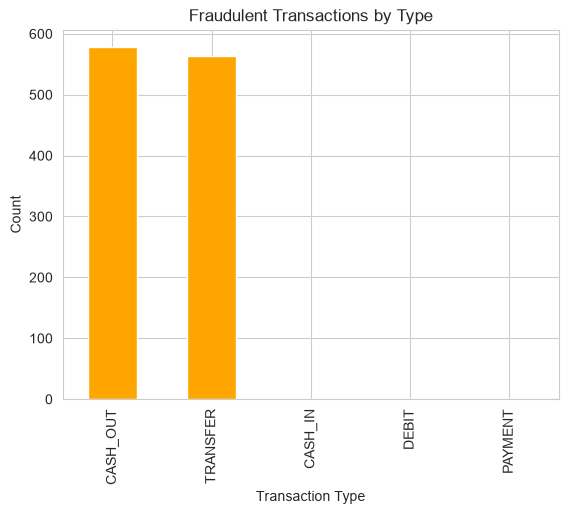

In [13]:
fraud_transactions = df.groupby('type')['isFraud'].sum().sort_values(ascending=False)   
fraud_transactions.plot(kind="bar", color="orange")
plt.title("Fraudulent Transactions by Type")
plt.xlabel("Transaction Type")
plt.ylabel("Count")

In [14]:
df["amount"].describe().astype(int)

count     1048575
mean       158666
std        264940
min             0
25%         12149
50%         76343
75%        213761
max      10000000
Name: amount, dtype: int64

Text(0, 0.5, 'Frequency')

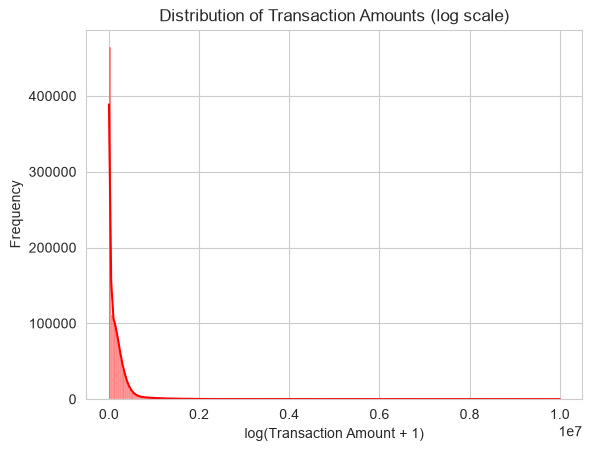

In [15]:
sns.histplot(df["amount"], bins=200, kde=True, color="red")
plt.title("Distribution of Transaction Amounts (log scale)")
plt.xlabel("log(Transaction Amount + 1)")
plt.ylabel("Frequency")

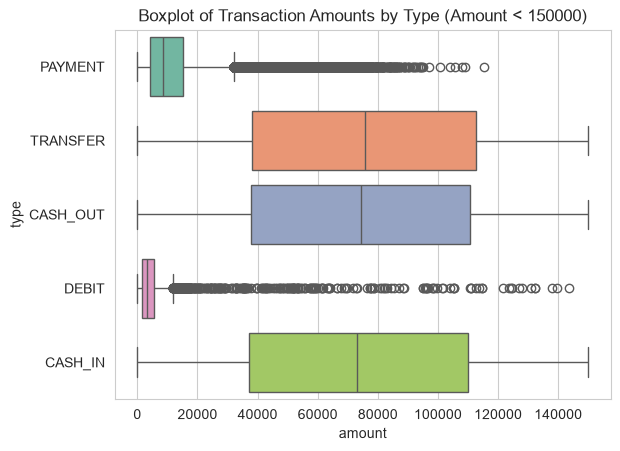

In [16]:
sns.boxplot(data=df[df["amount"]<150000], x="amount", y="type", palette="Set2")
plt.title("Boxplot of Transaction Amounts by Type (Amount < 150000)")  
plt.show()

In [17]:
df.columns

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='str')

In [18]:
df["BalanceDifference"] = df["oldbalanceOrg"] - df["newbalanceOrig"]
df["BalanceDifference"] = df["newbalanceOrig"] - df["oldbalanceOrg"]

In [19]:
(df["BalanceDifference"] < 0).sum()

np.int64(482134)

In [20]:
fraud = df['isFraud'].value_counts(normalize=True)*100

print(fraud)

isFraud
0    99.89109
1     0.10891
Name: proportion, dtype: float64


In [21]:
df = df.drop(['nameOrig','nameDest'], axis=1)

df.head()

,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,BalanceDifference
0,1,PAYMENT,9839.64,170136.0,160296.36,0.0,0.0,0,0,-9839.64
1,1,PAYMENT,1864.28,21249.0,19384.72,0.0,0.0,0,0,-1864.28
2,1,TRANSFER,181.00,181.0,0.00,0.0,0.0,1,0,-181.00
3,1,CASH_OUT,181.00,181.0,0.00,21182.0,0.0,1,0,-181.00
4,1,PAYMENT,11668.14,41554.0,29885.86,0.0,0.0,0,0,-11668.14


In [22]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()

df['type'] = encoder.fit_transform(df['type'])

df.head()

,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,BalanceDifference
0,1,3,9839.64,170136.0,160296.36,0.0,0.0,0,0,-9839.64
1,1,3,1864.28,21249.0,19384.72,0.0,0.0,0,0,-1864.28
2,1,4,181.00,181.0,0.00,0.0,0.0,1,0,-181.00
3,1,1,181.00,181.0,0.00,21182.0,0.0,1,0,-181.00
4,1,3,11668.14,41554.0,29885.86,0.0,0.0,0,0,-11668.14


In [23]:
mapping = dict(zip(encoder.classes_, encoder.transform(encoder.classes_)))

mapping

{'CASH_IN': np.int64(0),
 'CASH_OUT': np.int64(1),
 'DEBIT': np.int64(2),
 'PAYMENT': np.int64(3),
 'TRANSFER': np.int64(4)}

In [24]:
##Exploratory Data Analysis

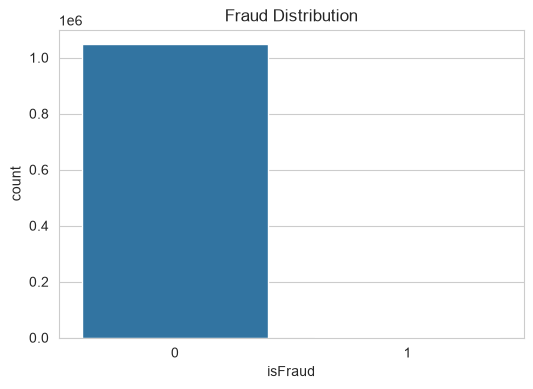

In [25]:
plt.figure(figsize=(6,4))

sns.countplot(x='isFraud', data=df)

plt.title("Fraud Distribution")

plt.show()

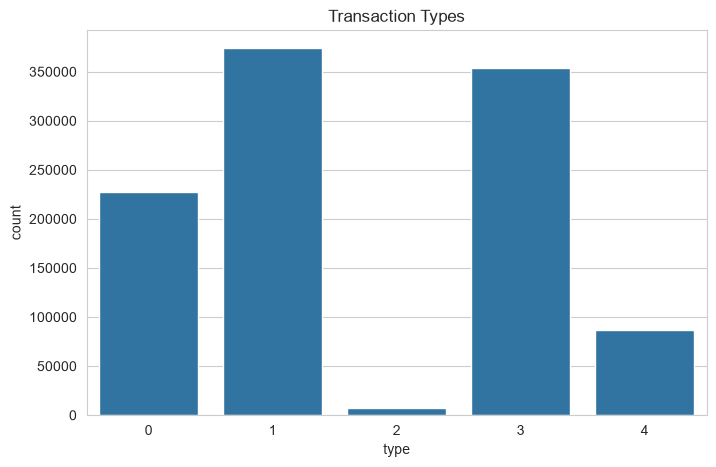

In [26]:
plt.figure(figsize=(8,5))

sns.countplot(x='type', data=df)

plt.title("Transaction Types")

plt.show()

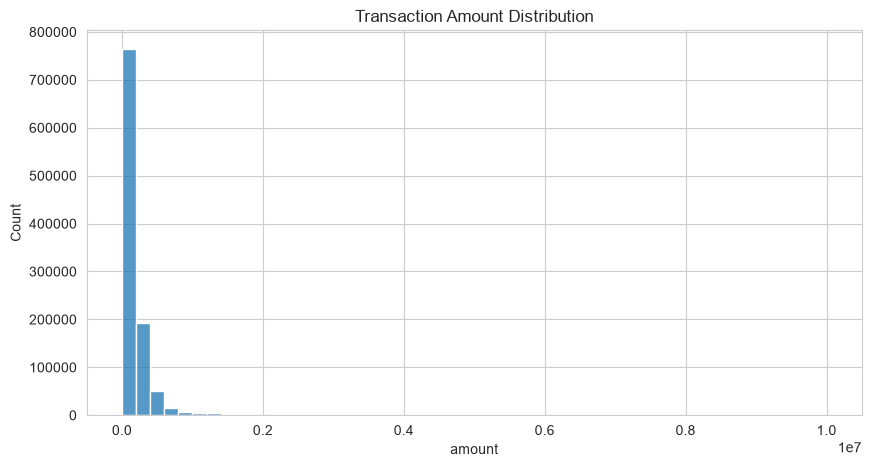

In [27]:
plt.figure(figsize=(10,5))

sns.histplot(df['amount'], bins=50)

plt.title("Transaction Amount Distribution")

plt.show()

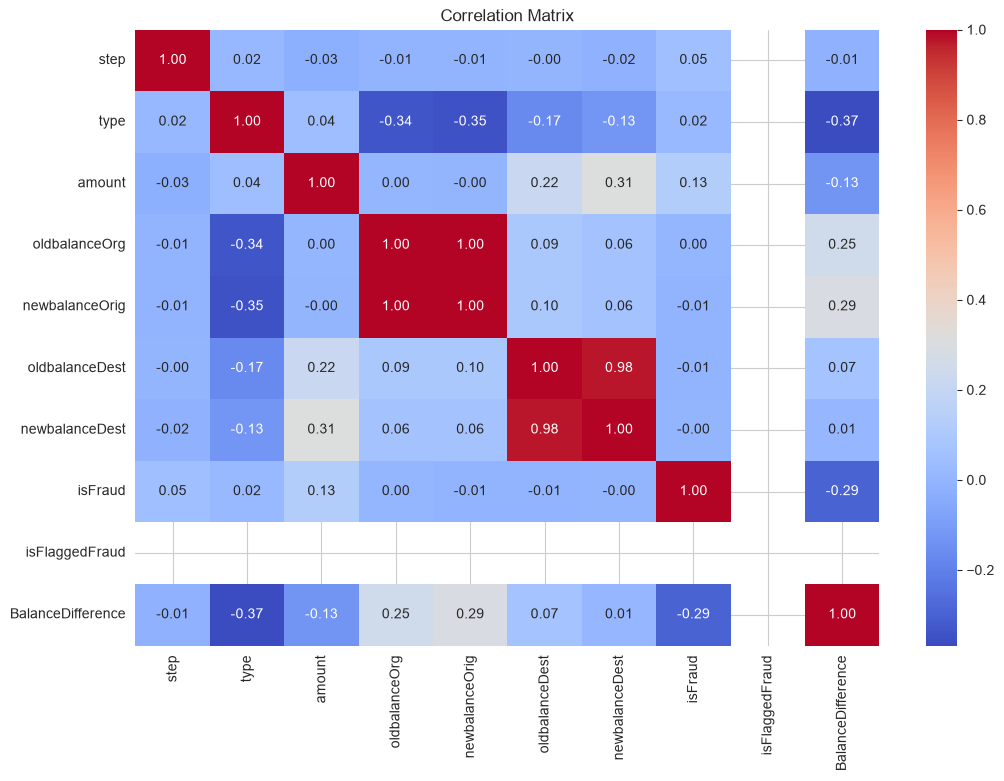

In [28]:
plt.figure(figsize=(12,8))

sns.heatmap(df.corr(),
            annot=True,
            cmap='coolwarm',
            fmt=".2f")

plt.title("Correlation Matrix")

plt.show()

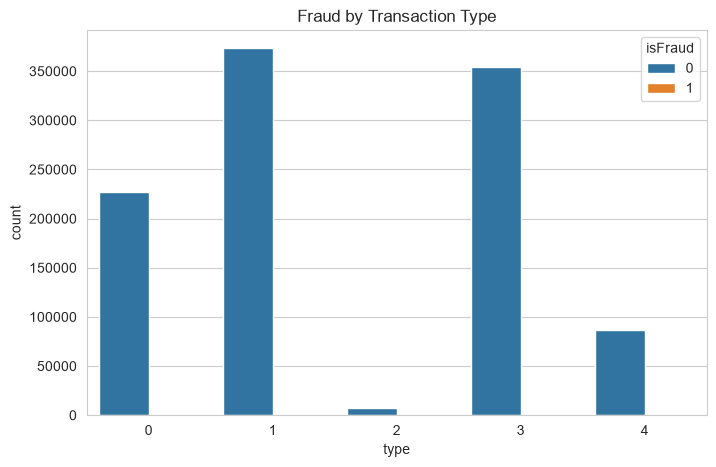

In [29]:
plt.figure(figsize=(8,5))

sns.countplot(
    x='type',
    hue='isFraud',
    data=df
)

plt.title("Fraud by Transaction Type")

plt.show()

In [30]:
X = df.drop('isFraud', axis=1)

y = df['isFraud']

print(X.shape)
print(y.shape)

(1048575, 9)
(1048575,)


In [31]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data :", X_train.shape)

print("Testing Data :", X_test.shape)

Training Data : (838860, 9)
Testing Data : (209715, 9)


In [32]:
df.to_csv("processed_fraud_data.csv", index=False)

print("Preprocessed dataset saved successfully.")

Preprocessed dataset saved successfully.


In [33]:
##Logistic Regression Model

In [34]:
from sklearn.linear_model import LogisticRegression

In [35]:
from sklearn.preprocessing import StandardScaler

In [36]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Scaling Completed")

Scaling Completed


In [37]:
log_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

log_model.fit(
    X_train_scaled,
    y_train
)

print("Logistic Regression Trained")

Logistic Regression Trained


In [38]:
log_predictions = log_model.predict(X_test_scaled)

log_predictions[:10]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [39]:
probability = log_model.predict_proba(X_test_scaled)

probability[:5]

array([[9.99763364e-01, 2.36635901e-04],
       [9.99949449e-01, 5.05513444e-05],
       [9.99672729e-01, 3.27270600e-04],
       [9.99616119e-01, 3.83880805e-04],
       [9.99996165e-01, 3.83499655e-06]])

In [40]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, log_predictions)

print("Accuracy :", accuracy)

Accuracy : 0.9991750709295949


In [41]:
from sklearn.metrics import precision_score

In [42]:
precision = precision_score(
    y_test,
    log_predictions
)

print("Precision :", precision)

Precision : 0.8160919540229885


In [43]:
from sklearn.metrics import classification_report , recall_score , confusion_matrix

In [44]:
recall = recall_score(
    y_test,
    log_predictions
)

print("Recall :", recall)

Recall : 0.31140350877192985


In [45]:
print(
    classification_report(
        y_test,
        log_predictions
    )
)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00    209487
           1       0.82      0.31      0.45       228

    accuracy                           1.00    209715
   macro avg       0.91      0.66      0.73    209715
weighted avg       1.00      1.00      1.00    209715



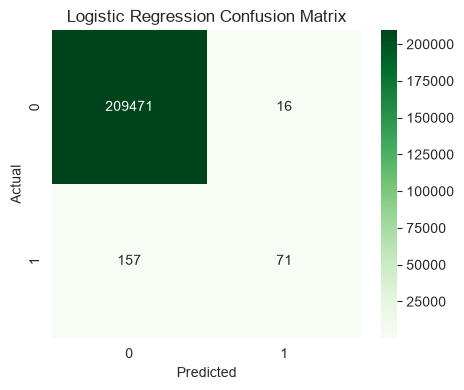

In [46]:
cm = confusion_matrix(
    y_test,
    log_predictions
)

plt.figure(figsize=(5,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens'
)

plt.title("Logistic Regression Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

In [47]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": log_model.coef_[0]
})

importance = importance.sort_values(
    by="Coefficient",
    key=abs,
    ascending=False
)

importance

,Feature,Coefficient
8,BalanceDifference,-1.664509
2,amount,-1.113782
6,newbalanceDest,-0.893346
0,step,0.756788
5,oldbalanceDest,-0.260636
4,newbalanceOrig,-0.228048
3,oldbalanceOrg,-0.155194
1,type,0.024119
7,isFlaggedFraud,0.000000


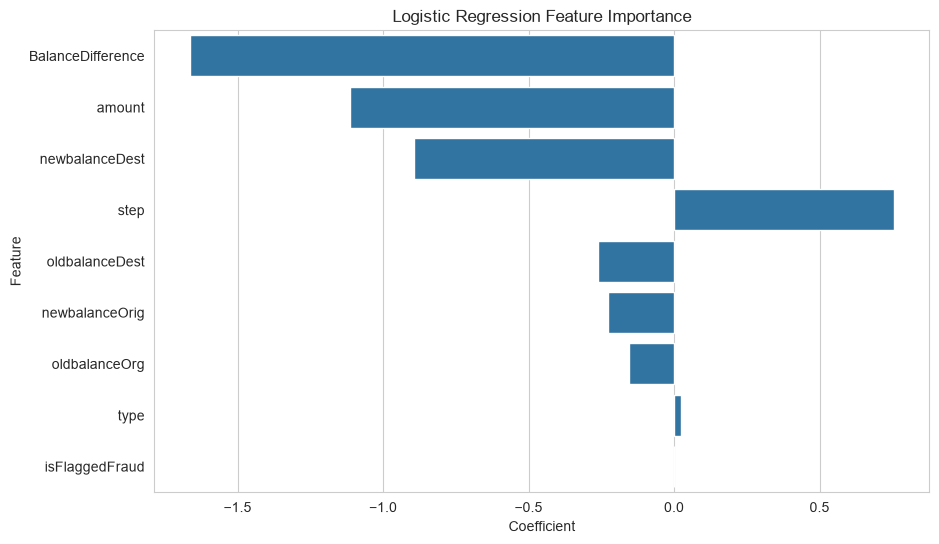

In [48]:
plt.figure(figsize=(10,6))

sns.barplot(
    x="Coefficient",
    y="Feature",
    data=importance
)

plt.title("Logistic Regression Feature Importance")

plt.show()

In [49]:
log_model.fit(
    X_train_scaled,
    y_train
)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [50]:
##Decision Tree & Random Forest

In [51]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

In [52]:
dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=10
)

dt_model.fit(X_train, y_train)

print("Decision Tree Model Trained Successfully")

Decision Tree Model Trained Successfully


In [53]:
dt_model.fit(X_train, y_train)


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at

In [54]:
dt_pred = dt_model.predict(X_test)

dt_pred[:10]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [55]:
dt_prob = dt_model.predict_proba(X_test)

In [56]:
dt_accuracy = accuracy_score(y_test, dt_pred)

print("Accuracy :", dt_accuracy)

Accuracy : 0.9996662136709343


In [57]:
dt_precision = precision_score(y_test, dt_pred)

print("Precision :", dt_precision)

Precision : 0.9488636363636364


In [58]:
dt_recall = recall_score(y_test, dt_pred)

print("Recall :", dt_recall)

Recall : 0.7324561403508771


In [59]:
dt_f1 = f1_score(y_test, dt_pred)

print("F1 Score :", dt_f1)

F1 Score : 0.8267326732673267


In [60]:
print(classification_report(
    y_test,
    dt_pred
))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00    209487
           1       0.95      0.73      0.83       228

    accuracy                           1.00    209715
   macro avg       0.97      0.87      0.91    209715
weighted avg       1.00      1.00      1.00    209715



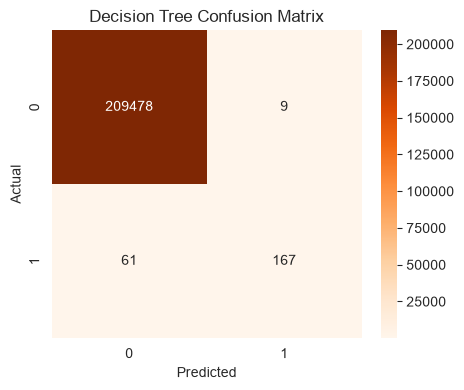

In [61]:
cm = confusion_matrix(
    y_test,
    dt_pred
)

plt.figure(figsize=(5,4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Oranges"
)

plt.title("Decision Tree Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

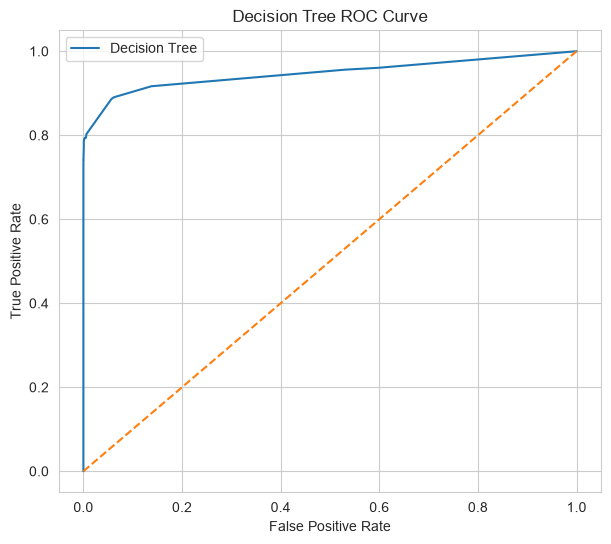

In [62]:
fpr, tpr, _ = roc_curve(
    y_test,
    dt_prob[:,1]
)

plt.figure(figsize=(7,6))

plt.plot(fpr,tpr,label="Decision Tree")

plt.plot([0,1],[0,1],'--')

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("Decision Tree ROC Curve")

plt.legend()

plt.show()

In [63]:
importance_dt = pd.DataFrame({

    "Feature":X.columns,

    "Importance":dt_model.feature_importances_

})

importance_dt = importance_dt.sort_values(
    by="Importance",
    ascending=False
)

importance_dt

,Feature,Importance
0,step,0.435792
8,BalanceDifference,0.311728
5,oldbalanceDest,0.076776
6,newbalanceDest,0.065618
1,type,0.047151
2,amount,0.045390
4,newbalanceOrig,0.011838
3,oldbalanceOrg,0.005707
7,isFlaggedFraud,0.000000


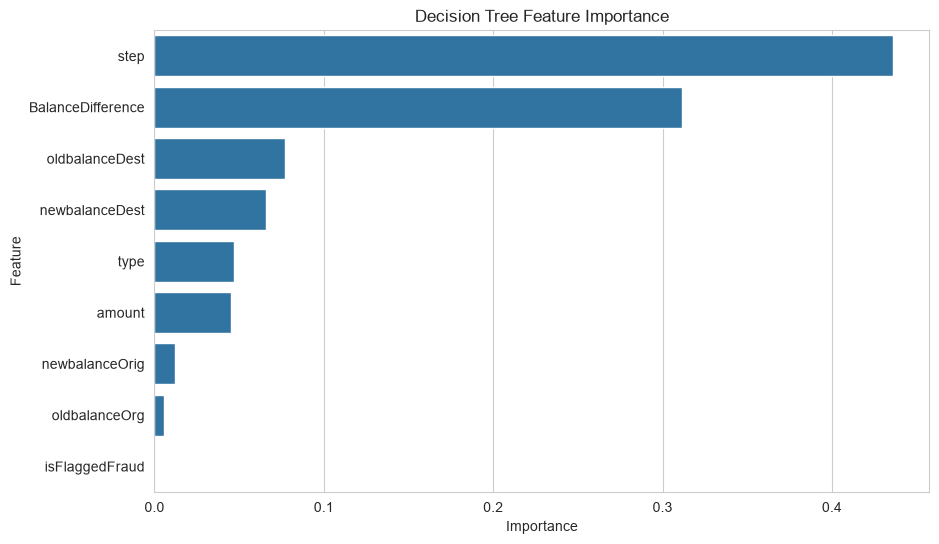

In [64]:
plt.figure(figsize=(10,6))

sns.barplot(
    x="Importance",
    y="Feature",
    data=importance_dt
)

plt.title("Decision Tree Feature Importance")

plt.show()

In [65]:
rf_model = RandomForestClassifier(

    n_estimators=100,

    random_state=42,

    max_depth=10,

    n_jobs=-1

)

rf_model.fit(
    X_train,
    y_train
)

print("Random Forest Trained Successfully")

Random Forest Trained Successfully


In [66]:
rf_model.fit(
    X_train,
    y_train
)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total n

In [67]:
rf_pred = rf_model.predict(X_test)

rf_pred[:10]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [68]:
rf_prob = rf_model.predict_proba(X_test)

In [69]:
rf_accuracy = accuracy_score(
    y_test,
    rf_pred
)

print("Accuracy :",rf_accuracy)

Accuracy : 0.9997091290561


In [70]:
rf_precision = precision_score(
    y_test,
    rf_pred
)

print("Precision :",rf_precision)

Precision : 0.9940828402366864


In [71]:
rf_recall = recall_score(
    y_test,
    rf_pred
)

print("Recall :",rf_recall)

Recall : 0.7368421052631579


In [72]:
rf_f1 = f1_score(
    y_test,
    rf_pred
)

print("F1 Score :",rf_f1)

F1 Score : 0.8463476070528967


In [73]:
rf_auc = roc_auc_score(
    y_test,
    rf_prob[:,1]
)

print("ROC AUC :",rf_auc)

ROC AUC : 0.9957052876621997


In [74]:
print(classification_report(
    y_test,
    rf_pred
))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00    209487
           1       0.99      0.74      0.85       228

    accuracy                           1.00    209715
   macro avg       1.00      0.87      0.92    209715
weighted avg       1.00      1.00      1.00    209715



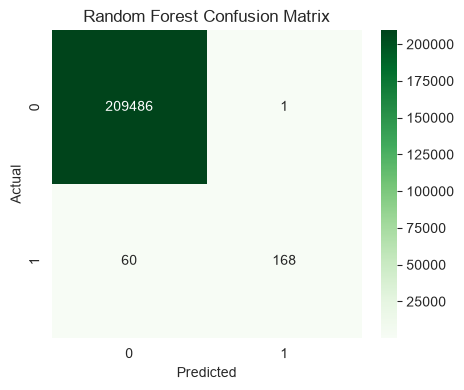

In [75]:
cm = confusion_matrix(
    y_test,
    rf_pred
)

plt.figure(figsize=(5,4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens"
)

plt.title("Random Forest Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

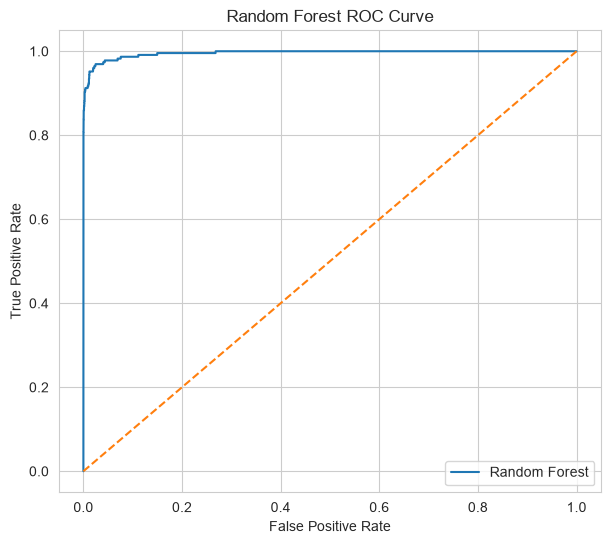

In [76]:
fpr, tpr, _ = roc_curve(
    y_test,
    rf_prob[:,1]
)

plt.figure(figsize=(7,6))

plt.plot(
    fpr,
    tpr,
    label="Random Forest"
)

plt.plot(
    [0,1],
    [0,1],
    '--'
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("Random Forest ROC Curve")

plt.legend()

plt.show()

In [77]:
importance_rf = pd.DataFrame({

    "Feature":X.columns,

    "Importance":rf_model.feature_importances_

})

importance_rf = importance_rf.sort_values(
    by="Importance",
    ascending=False
)

importance_rf

,Feature,Importance
0,step,0.304906
8,BalanceDifference,0.258871
6,newbalanceDest,0.141054
2,amount,0.095509
5,oldbalanceDest,0.081496
3,oldbalanceOrg,0.057866
4,newbalanceOrig,0.031147
1,type,0.029151
7,isFlaggedFraud,0.000000


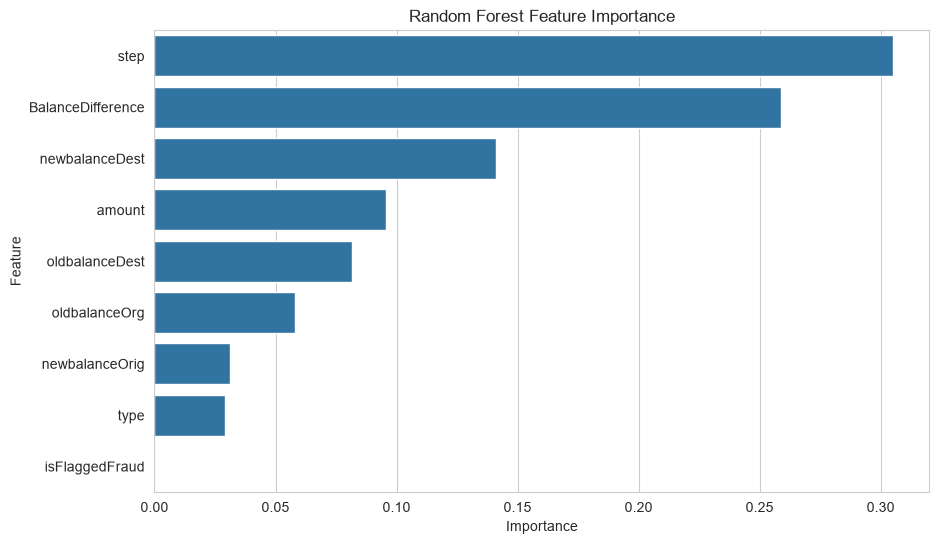

In [78]:
plt.figure(figsize=(10,6))

sns.barplot(

    x="Importance",

    y="Feature",

    data=importance_rf

)

plt.title("Random Forest Feature Importance")

plt.show()

In [79]:
log_auc = roc_auc_score(y_test, probability[:, 1])
dt_auc = roc_auc_score(y_test, dt_prob[:, 1])

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, log_predictions),
        dt_accuracy,
        rf_accuracy
    ],
    "Precision": [
        precision_score(y_test, log_predictions),
        dt_precision,
        rf_precision
    ],
    "Recall": [
        recall_score(y_test, log_predictions),
        dt_recall,
        rf_recall
    ],
    "F1 Score": [
        f1_score(y_test, log_predictions),
        dt_f1,
        rf_f1
    ],
    "ROC AUC": [
        log_auc,
        dt_auc,
        rf_auc
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.999175,0.816092,0.311404,0.450794,0.907375
1,Decision Tree,0.999666,0.948864,0.732456,0.826733,0.947195
2,Random Forest,0.999709,0.994083,0.736842,0.846348,0.995705


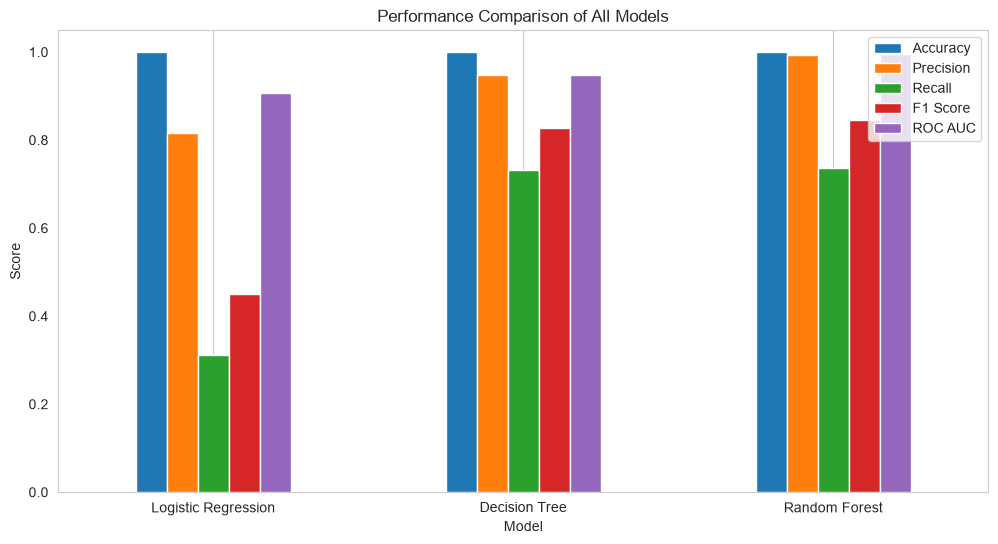

In [80]:
comparison.set_index("Model").plot(

    kind="bar",

    figsize=(12,6)

)

plt.title("Performance Comparison of All Models")

plt.ylabel("Score")

plt.xticks(rotation=0)

plt.grid(axis="y")

plt.show()

In [81]:
best_model = comparison.sort_values(
    by="Accuracy",
    ascending=False
)

best_model

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
2,Random Forest,0.999709,0.994083,0.736842,0.846348,0.995705
1,Decision Tree,0.999666,0.948864,0.732456,0.826733,0.947195
0,Logistic Regression,0.999175,0.816092,0.311404,0.450794,0.907375


In [82]:
import joblib

# Save the trained Random Forest model
joblib.dump(rf_model, "fraud_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [83]:
joblib.dump(encoder, "label_encoder.pkl")

print("Encoder saved successfully!")

Encoder saved successfully!


In [84]:
app_code = '''
import streamlit as st
import pandas as pd
import joblib

# Load Model
model = joblib.load("fraud_model.pkl")
encoder = joblib.load("label_encoder.pkl")

st.set_page_config(
    page_title="Financial Fraud Detection",
    page_icon="💳",
    layout="wide"
)

st.title("💳 Financial Fraud Detection System")
st.write("Predict whether a transaction is Fraud or Genuine")

st.sidebar.header("Transaction Details")

transaction_type = st.sidebar.selectbox(
    "Transaction Type",
    encoder.classes_
)

amount = st.sidebar.number_input(
    "Amount",
    min_value=0.0,
    value=1000.0
)

oldbalanceOrg = st.sidebar.number_input(
    "Old Balance Sender",
    value=0.0
)

newbalanceOrig = st.sidebar.number_input(
    "New Balance Sender",
    value=0.0
)

oldbalanceDest = st.sidebar.number_input(
    "Old Balance Receiver",
    value=0.0
)

newbalanceDest = st.sidebar.number_input(
    "New Balance Receiver",
    value=0.0
)

step = st.sidebar.slider(
    "Step",
    1,
    750,
    100
)

isFlaggedFraud = st.sidebar.selectbox(
    "Flagged Fraud",
    [0,1]
)

type_encoded = encoder.transform([transaction_type])[0]

features = pd.DataFrame({
    "step":[step],
    "type":[type_encoded],
    "amount":[amount],
    "oldbalanceOrg":[oldbalanceOrg],
    "newbalanceOrig":[newbalanceOrig],
    "oldbalanceDest":[oldbalanceDest],
    "newbalanceDest":[newbalanceDest],
    "isFlaggedFraud":[isFlaggedFraud]
})

if st.button("Predict"):

    prediction = model.predict(features)[0]

    probability = model.predict_proba(features)[0][1]

    st.subheader("Prediction")

    if prediction == 1:
        st.error("🚨 Fraud Transaction Detected")
    else:
        st.success("✅ Genuine Transaction")

    st.write(f"Fraud Probability: {probability*100:.2f}%")

st.markdown("---")
st.write("Developed using Python + Scikit-Learn + Streamlit")
'''

with open("app.py","w",encoding="utf-8") as f:
    f.write(app_code)

print("app.py created successfully!")

app.py created successfully!


In [85]:
import streamlit as st

uploaded_file = st.file_uploader(
    "Upload CSV",
    type=["csv"]
)

if uploaded_file:

    data = pd.read_csv(uploaded_file)

    prediction = model.predict(data)

    data["Prediction"] = prediction

    st.write(data.head())

    csv = data.to_csv(index=False)

    st.download_button(
        "Download Results",
        csv,
        "prediction.csv",
        "text/csv"
    )

2026-07-17 15:02:29.780 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-07-17 15:02:29.785 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-07-17 15:02:29.806 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-07-17 15:02:34.126 
  command:

    streamlit run c:\Users\dell\AppData\Local\Programs\Python\Python314\Lib\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-07-17 15:02:34.129 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-07-17 15:02:34.132 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


In [86]:
model = rf_model
print(model.feature_names_in_)

['step' 'type' 'amount' 'oldbalanceOrg' 'newbalanceOrig' 'oldbalanceDest'
 'newbalanceDest' 'isFlaggedFraud' 'BalanceDifference']


In [87]:
st.write("Model expects:")
st.write(model.feature_names_in_)

2026-07-17 15:02:34.183 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-07-17 15:02:34.184 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-07-17 15:02:34.186 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-07-17 15:02:34.224 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-07-17 15:02:34.227 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-07-17 15:02:34.230 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-07-17 15:02:34.233 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


In [88]:
# Create features DataFrame matching the model input structure
features = pd.DataFrame({
    "step": [1],
    "type": [1],  # encoded transaction type
    "amount": [1000.0],
    "oldbalanceOrg": [0.0],
    "newbalanceOrig": [0.0],
    "oldbalanceDest": [0.0],
    "newbalanceDest": [0.0],
    "isFlaggedFraud": [0]
})

print(features.columns.tolist())

['step', 'type', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'isFlaggedFraud']


In [89]:
features = features.reindex(columns=model.feature_names_in_, fill_value=0)

In [90]:
prediction = model.predict(features)[0]

In [91]:
import joblib

model = joblib.load("fraud_model.pkl")

print(model.feature_names_in_)

['step' 'type' 'amount' 'oldbalanceOrg' 'newbalanceOrig' 'oldbalanceDest'
 'newbalanceDest' 'isFlaggedFraud' 'BalanceDifference']


In [ ]:
X = ...
X = df.drop("isFraud", axis=1)
y = df["isFraud"]

model.fit(X, y)

TypeError: float() argument must be a string or a real number, not 'ellipsis'